# Exploratory shape analysis (before the final SSM)

A fast, throwaway-quality first pass over the **healthy whole-gland** cohort: clean masks →
extract surfaces → ShapeWorks particle correspondence → Procrustes + PCA → inspect.
The question we want answered: does the cohort produce a sensible low-dimensional shape
space, and does it separate by source dataset / acquisition site or gland size?

**Setup**
- `pip install -e ".[dev,analysis]"` (or `pip install -r requirements-dev.txt`).
- **ShapeWorks is not pip-installable.** Install it from
  https://sciinstitute.github.io/ShapeWorks/ and run *this notebook from the ShapeWorks
  environment* so `import shapeworks` works and the `shapeworks` CLI is on PATH. Every step
  except the correspondence cell works without it.
- Point `SAML_DIR` / `PROSTATE158_DIR` at the two dataset roots. SAML is the multi-center
  prostate set (BIDMC, BMC, HK, I2CVB, RUNMC, UCL — the last two overlap with PROMISE12);
  we use it in place of PROMISE12 so each acquisition site becomes its own labelled source.

In [42]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from shape_modeling.io.reader import discover_cases
from shape_modeling.analysis import (
    build_grouped_cohort, clean_mask, extract_surface, CleanConfig,
    gpa, build_ssm, mode_shape,
)

# --- edit these two paths ---
SAML_DIR = Path("../SAML")              # multi-center prostate set (incl. PROMISE12 centers)
PROSTATE158_DIR = Path("../Prostate158")

# ALL-DATA run: SAML (healthy, multi-center) + ALL Prostate158 (healthy AND cancer). This is a
# pooled ANATOMICAL basis that also covers diseased glands -- it is NOT a substrate for the
# cancer-vs-healthy question: every cancer case is Prostate158, so "cancer" is confounded with
# source / annotation / site (do that test in the Prostate158-only grouped run). Note the OWN
# WORK_DIR -- a different cohort than the healthy-only SAML run, so it must not clobber that cache.
NUM_PARTICLES = 1024
WORK_DIR = Path(f"../shapeworks_work_alldata_{NUM_PARTICLES}p")

## 1. Load both datasets and build the all-data cohort

`discover_cases` is run per dataset so the **source** label is unambiguous. SAML bundles
several acquisition sites under one root; `discover_cases` namespaces the case ids by
sub-folder (e.g. `BIDMC/Case00`) so cases from different sites don't collide on disk during
the ShapeWorks step. We then relabel each SAML entry's source to its **center**, so the mode
scatter is coloured per acquisition site. `build_grouped_cohort` keeps **every** case with an
organ segmentation — healthy *and* cancer — tagging each with `is_cancer`. SAML has no tumour
segmentations, so all its cases are healthy and **every cancer case is Prostate158**.

In [43]:
ds_saml = discover_cases(SAML_DIR, default_mri_type="T2W")
ds_prostate = discover_cases(PROSTATE158_DIR, default_mri_type="T2W")
print("SAML:", len(ds_saml), "cases |", "Prostate158:", len(ds_prostate), "cases")

# build_grouped_cohort keeps EVERY case with an organ seg (healthy + cancer), tagging is_cancer.
# SAML has no tumour segs -> all SAML cases are is_cancer=False; every cancer case is Prostate158.
cohort = build_grouped_cohort({"SAML": ds_saml, "Prostate158": ds_prostate})

# Drop acquisition sites whose whole-gland masks are unusable. I2CVB's segmentations have a flat
# (planar) truncation -- the gland is cut off by the annotation crop rather than following the real
# boundary -- so pooling them would inject a spurious flat-face shape mode. Exclude the whole site.
# SAML case ids are namespaced by sub-folder ("I2CVB/Case00"); Prostate158 ids ("022") have no "/"
# so split("/")[0] is the id itself and never matches a site name -> only SAML sites are filtered.
EXCLUDE_SITES = {"I2CVB"}
dropped = [e.case_id for e in cohort if e.case_id.split("/")[0] in EXCLUDE_SITES]
cohort = [e for e in cohort if e.case_id.split("/")[0] not in EXCLUDE_SITES]
if dropped:
    print(f"excluded {len(dropped)} cases from sites {sorted(EXCLUDE_SITES)}: "
          f"{dropped[0]} ... {dropped[-1]}")

# SAML case ids are namespaced by center ("BIDMC/Case00"); relabel each entry's source to its
# center so each acquisition site is coloured separately in the scatter below.
for e in cohort:
    if e.source == "SAML":
        e.source = "SAML:" + e.case_id.split("/")[0]

n_cancer = sum(e.is_cancer for e in cohort)
print(f"\nAll-data cohort: {len(cohort)} cases  ({n_cancer} cancer, {len(cohort) - n_cancer} healthy)")
from collections import Counter
for s, n in sorted(Counter(e.source for e in cohort).items()):
    nc = sum(e.is_cancer for e in cohort if e.source == s)
    print(f"  {s:<18}{n:>4}  ({nc} cancer)")

print(f"\n{'case':<24}{'source':<18}{'cancer':>7}{'volume_cm3':>12}")
print("-" * 61)
for e in cohort:
    print(f"{e.case_id:<24}{e.source:<18}{str(e.is_cancer):>7}{e.volume_cm3:>12.1f}")

sources = np.array([e.source for e in cohort])
volumes = np.array([e.volume_cm3 for e in cohort])
is_cancer = np.array([e.is_cancer for e in cohort])

SAML: 116 cases | Prostate158: 139 cases
excluded 19 cases from sites ['I2CVB']: I2CVB/Case00 ... I2CVB/Case18

All-data cohort: 236 cases  (83 cancer, 153 healthy)
  Prostate158        139  (83 cancer)
  SAML:BIDMC          12  (0 cancer)
  SAML:BMC            30  (0 cancer)
  SAML:HK             12  (0 cancer)
  SAML:RUNMC          30  (0 cancer)
  SAML:UCL            13  (0 cancer)

case                    source             cancer  volume_cm3
-------------------------------------------------------------
022                     Prostate158         False        70.3
023                     Prostate158         False        52.8
024                     Prostate158         False        88.2
026                     Prostate158         False        22.8
028                     Prostate158         False        25.7
034                     Prostate158         False       175.4
037                     Prostate158         False        99.2
040                     Prostate158         False    

## 2. Clean masks and extract surfaces

Keep the largest connected component, fill interior holes, and triangulate with marching
cubes (vertices placed in physical mm). Surfaces here are for inspection — the
correspondence step feeds the *segmentations* to ShapeWorks.

case                   raw vox  clean vox   verts   faces     bbox mm (x,y,z)
-----------------------------------------------------------------------------
022                     145241     144165   34952   69900          (50,59,64)
023                     109017     104860   27168   54332          (55,40,42)
024                     182171     181180   41708   83412          (64,53,57)


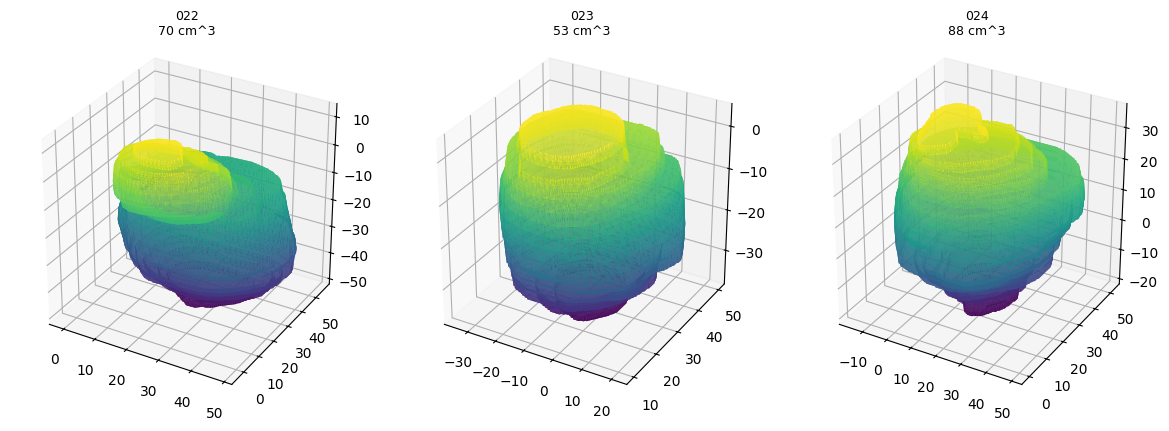

In [44]:
clean_cfg = CleanConfig(keep_largest=True, fill_holes=True, smooth_sigma=1.0)

# Render the first few glands as a sanity check, and report the mesh/volume numbers per shape.
n_show = min(3, len(cohort))
fig = plt.figure(figsize=(4 * n_show, 4))
print(f"{'case':<20}{'raw vox':>10}{'clean vox':>11}{'verts':>8}{'faces':>8}{'bbox mm (x,y,z)':>20}")
print("-" * 77)
for i in range(n_show):
    e = cohort[i]
    cleaned = clean_mask(e.organ.array, clean_cfg)
    surf = extract_surface(cleaned, e.organ)
    ext = surf.verts.max(0) - surf.verts.min(0)
    print(f"{e.case_id:<20}{int((e.organ.array > 0).sum()):>10}{int(cleaned.sum()):>11}"
          f"{len(surf.verts):>8}{len(surf.faces):>8}"
          f"{f'({ext[0]:.0f},{ext[1]:.0f},{ext[2]:.0f})':>20}")
    ax = fig.add_subplot(1, n_show, i + 1, projection="3d")
    ax.plot_trisurf(surf.verts[:, 0], surf.verts[:, 1], surf.faces, surf.verts[:, 2],
                    cmap="viridis", linewidth=0, antialiased=True)
    ax.set_title(f"{e.case_id}\n{e.volume_cm3:.0f} cm^3", fontsize=9)
    ax.set_box_aspect((1, 1, 1))
plt.tight_layout(); plt.show()

## 3. Particle correspondence (ShapeWorks)

Grooms each whole-gland mask (antialias → isotropic resample → distance transform) and runs
the particle optimizer. The result is **cached** in `WORK_DIR/particles.npz`, so re-running
this cell is instant once the optimizer has run once.

> Requires ShapeWorks. If `import shapeworks` fails, see the setup note at the top.

In [45]:
from shape_modeling.analysis import run_shapeworks, ShapeWorksConfig
from shape_modeling.analysis.correspondence import ParticleSystem, particle_spread_ratio

# use_cache=True: WORK_DIR is per-particle-count, so the cache can't mix resolutions.
sw_cfg = ShapeWorksConfig(num_particles=NUM_PARTICLES, iterations=1000, work_dir=WORK_DIR, use_cache=True)

# Self-clean a stale/degenerate cache (e.g. the pre-grooming-fix scattered run) so the fixed
# grooming re-optimizes; a healthy cache (spread ratio ~1) is kept, so reruns stay instant.
cache = WORK_DIR / "particles.npz"
if cache.exists() and sw_cfg.max_spread_ratio is not None:
    old = ParticleSystem.load(cache)
    if old.case_ids == [e.case_id for e in cohort] and \
            particle_spread_ratio(old, cohort) > sw_cfg.max_spread_ratio:
        cache.unlink()
        print("dropped pre-fix scattered cache -> will re-groom + re-optimize")

system = run_shapeworks(cohort, sw_cfg)        # (S, M, 3); cached after the first good run
print("particles:", system.particles.shape, "for", len(system.case_ids), "subjects")
print(f"spread ratio: {particle_spread_ratio(system, cohort):.2f}  (healthy ~1.0-1.3)")
assert system.case_ids == [e.case_id for e in cohort]   # rows align with metadata

particles: (236, 1024, 3) for 236 subjects
spread ratio: 0.97  (healthy ~1.0-1.3)


### Diagnostic: is the cross-dataset alignment actually working?

Opening the groomed files in ShapeWorks Studio and seeing each gland sit in a **different part
of its box** is *expected* and **not** an alignment failure: the last grooming step
`fitRegion`-crops every subject to its **own** gland bounding box, so each groomed image has its
own grid, origin and extent. Where a gland sits *within its own crop box* says nothing about
whether the shapes co-locate in **world space** — which is the only thing the COM-centre + ICP
alignment touches (it runs *before* the crop).

So judge alignment in world coordinates, two ways:

1. **Groomed-gland world COMs should cluster.** COM-centring puts each shape at *its own grid
   centre* (a different physical point per subject, since image sizes differ); the ICP-to-reference
   step is what actually pulls them together. Tightly clustered COMs (std a few mm, no per-source
   offset) ⇒ ICP converged. Tens of mm of scatter, or a systematic per-dataset shift ⇒ a cohort is
   mis-registered.
2. **The optimizer's `*_world.particles` should overlap into one blob.** These are the
   Procrustes-aligned particles the SSM is actually built from — the real test of correspondence.

Reads straight off disk (no `system`/`cohort` needed), so point `DIAG_WORK_DIR` at whichever run
you opened in Studio.

236 groomed glands across 6 sources
world COM std per axis [x y z] mm: [2.75 5.73 7.51]  | bounding gap mm: [26.5 33.  35.6]

source           n       mean COM (x,y,z) mm
BIDMC           12       [ 18.5  15.7 -17.7]
BMC             30       [ 18.4  18.  -19.9]
HK              12       [ 19.   17.3 -21.8]
Prostate158    139       [ 18.6  21.6 -24.3]
RUNMC           30       [ 19.4  21.3 -23.2]
UCL             13       [ 18.7  23.  -27. ]


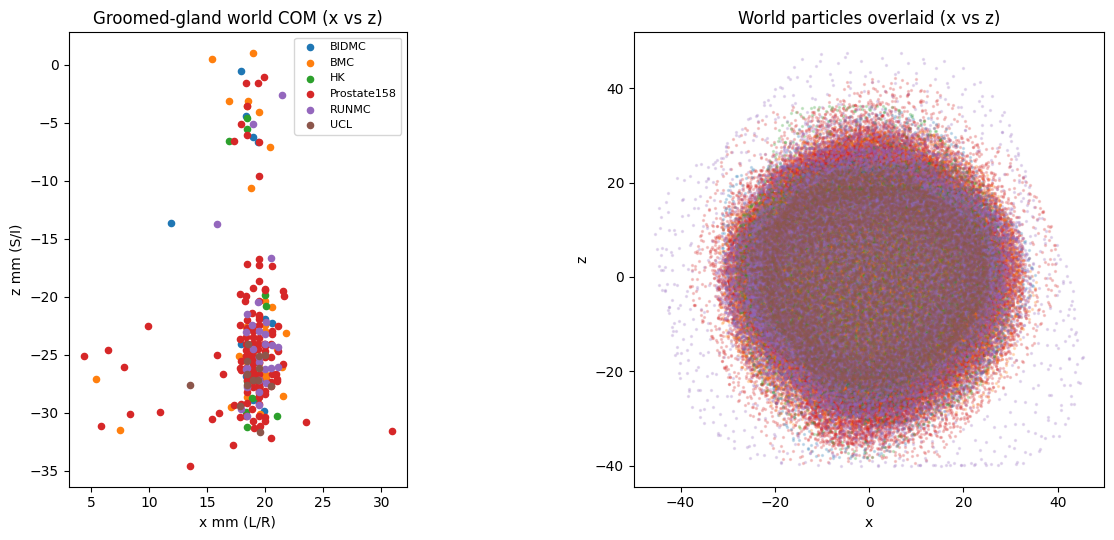


READ IT: left = a tight blob with no per-source separation (COM std a few mm), and right = a single overlapping cloud  =>  alignment is fine and the Studio 'different box' look is just the per-subject crop. A per-source shift on the left, or separated clouds on the right, means a dataset is mis-registered (or this is a stale pre-grooming-fix run -- re-optimize).


In [46]:
import itertools

import SimpleITK as sitk

DIAG_WORK_DIR = WORK_DIR   # this all-data run (built above); repoint to compare another run in Studio

def _source(stem):  # SAML/PROMISE12 cases are "<SITE>__CaseNN"; Prostate158 are bare numbers
    return stem.split("__")[0] if "__" in stem else "Prostate158"

# (1) world-space centre of mass of each groomed gland --------------------------------------------
stems, coms = [], []
for p in sorted((DIAG_WORK_DIR / "groomed").glob("*_DT.nrrd")):
    dt = sitk.ReadImage(str(p))
    idx = np.argwhere(sitk.GetArrayFromImage(dt) <= 0)            # DT <= 0 is interior, (z, y, x)
    coms.append(dt.TransformContinuousIndexToPhysicalPoint(idx.mean(0)[::-1].tolist()))  # -> (x, y, z)
    stems.append(p.name[: -len("_DT.nrrd")])
coms = np.asarray(coms)
srcs = np.array([_source(s) for s in stems])
src_names = sorted(set(srcs))

print(f"{len(stems)} groomed glands across {len(src_names)} sources")
print("world COM std per axis [x y z] mm:", np.round(coms.std(0), 2),
      " | bounding gap mm:", np.round(np.ptp(coms, axis=0), 1))
print(f"\n{'source':<14}{'n':>4}{'mean COM (x,y,z) mm':>26}")
for s in src_names:
    m = srcs == s
    print(f"{s:<14}{int(m.sum()):>4}{str(np.round(coms[m].mean(0), 1)):>26}")

# (2) optimizer world particles (Procrustes-aligned) ----------------------------------------------
pdir = DIAG_WORK_DIR / "shape_model_particles"
world = {f.name[: -len("_DT_world.particles")]: np.loadtxt(f)
         for f in sorted(pdir.glob("*_DT_world.particles"))}

# --- plot: COMs (left) and overlaid world particles (right), coloured by source ------------------
colors = dict(zip(src_names, itertools.cycle(plt.cm.tab10.colors)))
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5.5))
for s in src_names:
    m = srcs == s
    axL.scatter(coms[m, 0], coms[m, 2], s=20, color=colors[s], label=s)   # x vs z = L/R vs S/I
axL.set(title="Groomed-gland world COM (x vs z)", xlabel="x mm (L/R)", ylabel="z mm (S/I)")
axL.set_aspect("equal"); axL.legend(fontsize=8)
for stem, pts in world.items():
    axR.scatter(pts[:, 0], pts[:, 2], s=2, alpha=0.2, color=colors[_source(stem)])
axR.set(title="World particles overlaid (x vs z)", xlabel="x", ylabel="z"); axR.set_aspect("equal")
plt.tight_layout(); plt.show()

print("\nREAD IT: left = a tight blob with no per-source separation (COM std a few mm), and right = "
      "a single overlapping cloud  =>  alignment is fine and the Studio 'different box' look is just "
      "the per-subject crop. A per-source shift on the left, or separated clouds on the right, means "
      "a dataset is mis-registered (or this is a stale pre-grooming-fix run -- re-optimize).")

## 4. Procrustes align + ComBat harmonization + PCA

Generalized Procrustes removes pose and scale; PCA over the aligned particles gives the mean
shape, principal modes, eigenvalues, and per-subject scores.

This is a **multi-center** cohort, so we harmonize between the two stages: GPA → **ComBat on
acquisition site** (protecting raw gland size) → re-GPA → PCA. ComBat corrects feature-by-feature
on *corresponded* points, so it sits **after** ShapeWorks, not before. The canonical `model`
everything downstream is built on is the harmonized one; the raw fit is kept as `model_raw` purely
as the baseline the section-6 site diagnostics are measured against.

ComBat batches on **centre**, and every cancer case lives in one centre (Prostate158), so the
healthy-vs-cancer contrast is *within* a batch — one additive+scale correction is applied uniformly
to all Prostate158 glands, leaving that contrast intact. Harmonization here only cleans up the
*between-site* anatomy of this descriptive basis; it does **not** turn it into a substrate for the
cancer question (still source-confounded — do that test in the Prostate158-only grouped run).

In [47]:
from shape_modeling.analysis import combat_harmonize, centroid_size

# Raw GPA + PCA, kept as `model_raw`: the un-harmonized baseline the section-6 site diagnostics
# are measured against (you can't show ComBat removed a confound without the "before").
aligned_raw, mean_shape_raw = gpa(system.particles, scale=True)
model_raw = build_ssm(aligned_raw)

# --- Production model: ComBat-harmonize on acquisition site, then re-fit -------------------------
# Multi-center pooling injects a site confound into the leading modes. Remove it from the
# COORDINATES before PCA so the basis encodes anatomy, not scanner. Raw gland size is a PROTECTED
# covariate, so genuine size variation survives. ComBat batches on centre, so the within-Prostate158
# healthy-vs-cancer contrast is untouched (see the section-4 note).
center = np.array([s.split(":")[-1] for s in sources])   # BIDMC/BMC/HK/RUNMC/UCL/Prostate158
raw_size = centroid_size(system.particles)               # pre-GPA size (mm), the protected covariate
harm_coords = combat_harmonize(aligned_raw, center, raw_size, covariate_names=["centroid_size"])
aligned, mean_shape = gpa(harm_coords, scale=True)        # re-GPA absorbs ComBat's small pose drift
model = build_ssm(aligned)                                # <- canonical model; everything below uses it

print(f"{model.n_modes} modes over {model.n_points} points  (ComBat-harmonized on centre)")
print("variance explained by first 5 modes:")
print("  harmonized (model)    :", np.round(model.explained_variance_ratio[:5], 3))
print("  raw        (model_raw):", np.round(model_raw.explained_variance_ratio[:5], 3))

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
235 modes over 1024 points  (ComBat-harmonized on centre)
variance explained by first 5 modes:
  harmonized (model)    : [0.261 0.135 0.094 0.08  0.067]
  raw        (model_raw): [0.246 0.139 0.103 0.091 0.078]


## 5. Inspect

Everything below inspects the **harmonized** `model` (the canonical, de-confounded basis from
section 4). Section 6 then quantifies the site confound in the raw `model_raw` and shows it's
gone here.

### Eigenvalue decay (scree) + cumulative variance
How many modes actually matter?

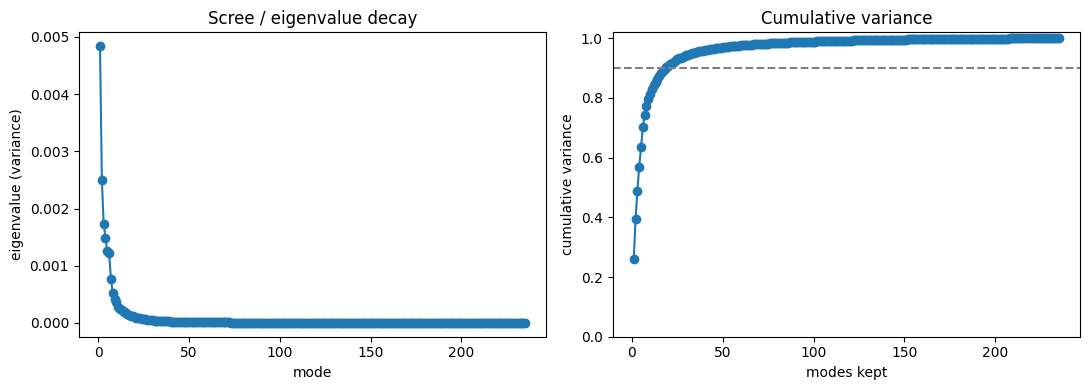

mode      eigenvalue   var ratio  cumulative
--------------------------------------------
1           0.004839       0.261       0.261
2           0.002506       0.135       0.396
3           0.001736       0.094       0.489
4           0.001492       0.080       0.570
5            0.00125       0.067       0.637
6           0.001218       0.066       0.703
7          0.0007742       0.042       0.745
8          0.0005225       0.028       0.773
modes to reach 90% variance: 19 / 235
modes to reach 95% variance: 34 / 235
modes to reach 99% variance: 105 / 235


In [48]:
k = model.n_modes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(np.arange(1, k + 1), model.eigenvalues, "o-")
ax1.set(xlabel="mode", ylabel="eigenvalue (variance)", title="Scree / eigenvalue decay")
ax2.plot(np.arange(1, k + 1), np.cumsum(model.explained_variance_ratio), "o-")
ax2.axhline(0.9, ls="--", c="grey"); ax2.set_ylim(0, 1.02)
ax2.set(xlabel="modes kept", ylabel="cumulative variance", title="Cumulative variance")
plt.tight_layout(); plt.show()

cum = np.cumsum(model.explained_variance_ratio)
print(f"{'mode':<6}{'eigenvalue':>14}{'var ratio':>12}{'cumulative':>12}")
print("-" * 44)
for i in range(min(8, k)):
    print(f"{i+1:<6}{model.eigenvalues[i]:>14.4g}{model.explained_variance_ratio[i]:>12.3f}{cum[i]:>12.3f}")
for thr in (0.90, 0.95, 0.99):
    print(f"modes to reach {thr:.0%} variance: {int(np.searchsorted(cum, thr) + 1)} / {k}")

### Mode scatter, coloured by source dataset and by gland volume
Does shape separate by where the scan came from, or just track size?

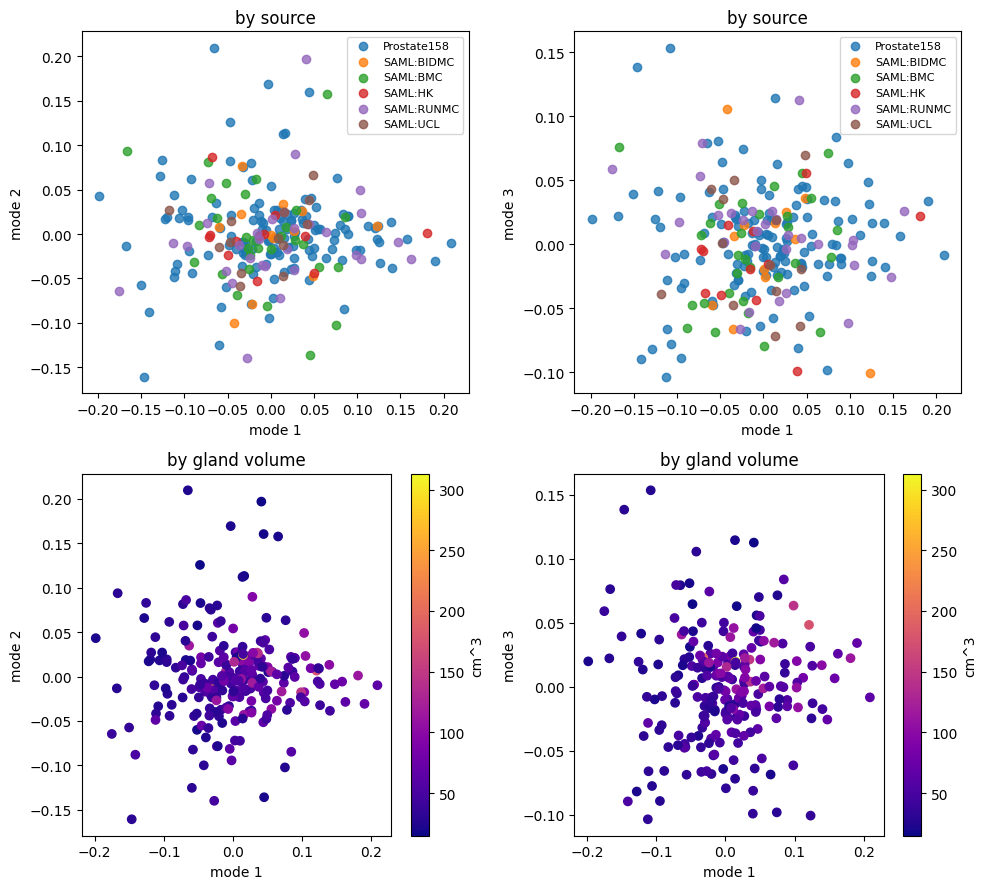

mean score by source
source              n       m1       m2       m3
------------------------------------------------
Prostate158       139    0.002    0.002    0.002
SAML:BIDMC         12    0.005   -0.004   -0.004
SAML:BMC           30   -0.012   -0.002   -0.006
SAML:HK            12   -0.005   -0.002   -0.013
SAML:RUNMC         30    0.008   -0.006    0.007
SAML:UCL           13   -0.012   -0.001   -0.006

mode vs gland volume (Pearson r, p):
  mode 1: r=+0.320  p=4.9e-07
  mode 2: r=-0.058  p=0.37
  mode 3: r=+0.119  p=0.067


In [49]:
from scipy import stats

src_names = sorted(set(sources))
src_to_int = {s: i for i, s in enumerate(src_names)}
src_idx = np.array([src_to_int[s] for s in sources])

pairs = [(0, 1), (0, 2)]
fig, axes = plt.subplots(2, len(pairs), figsize=(5 * len(pairs), 9))
for col, (a, b) in enumerate(pairs):
    # by source
    ax = axes[0, col]
    for s in src_names:
        m = sources == s
        ax.scatter(model.scores[m, a], model.scores[m, b], label=s, alpha=0.8)
    ax.set(xlabel=f"mode {a+1}", ylabel=f"mode {b+1}", title="by source")
    ax.legend(fontsize=8)
    # by volume
    ax = axes[1, col]
    sc = ax.scatter(model.scores[:, a], model.scores[:, b], c=volumes, cmap="plasma")
    ax.set(xlabel=f"mode {a+1}", ylabel=f"mode {b+1}", title="by gland volume")
    fig.colorbar(sc, ax=ax, label="cm^3")
plt.tight_layout(); plt.show()

modes_shown = sorted({m for pair in pairs for m in pair})
# mean score per source for the displayed modes
hdr = "".join(f"{'m' + str(m + 1):>9}" for m in modes_shown)
print(f"mean score by source\n{'source':<16}{'n':>5}{hdr}")
print("-" * (21 + 9 * len(modes_shown)))
for s in src_names:
    msk = sources == s
    row = "".join(f"{model.scores[msk, m].mean():>9.3f}" for m in modes_shown)
    print(f"{s:<16}{int(msk.sum()):>5}{row}")
# does each mode track gland size?
print("\nmode vs gland volume (Pearson r, p):")
for m in modes_shown:
    r, p = stats.pearsonr(model.scores[:, m], volumes)
    print(f"  mode {m + 1}: r={r:+.3f}  p={p:.2g}")

### Pairplot of the first modes

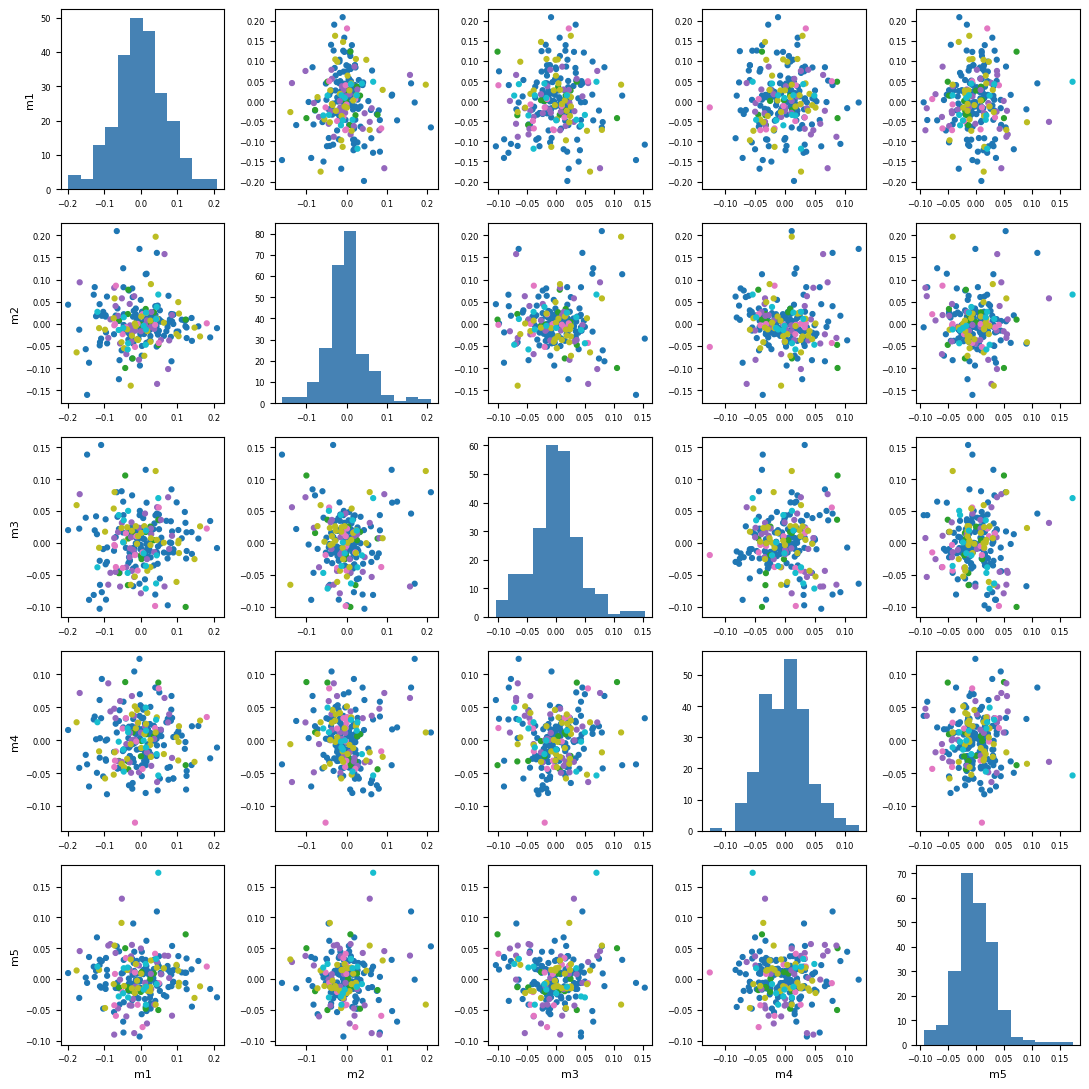

mode       mean      std      min      max     skew
---------------------------------------------------
1        -0.000    0.069   -0.199    0.209    0.072
2         0.000    0.050   -0.161    0.210    0.711
3        -0.000    0.042   -0.103    0.153    0.255
4        -0.000    0.039   -0.125    0.123    0.171
5        -0.000    0.035   -0.093    0.173    0.624


In [50]:
n_modes_plot = min(5, model.n_modes)
fig, axes = plt.subplots(n_modes_plot, n_modes_plot, figsize=(2.2 * n_modes_plot, 2.2 * n_modes_plot))
for i in range(n_modes_plot):
    for j in range(n_modes_plot):
        ax = axes[i, j]
        if i == j:
            ax.hist(model.scores[:, i], bins=12, color="steelblue")
        else:
            ax.scatter(model.scores[:, j], model.scores[:, i], c=src_idx, cmap="tab10", s=12)
        if i == n_modes_plot - 1:
            ax.set_xlabel(f"m{j+1}", fontsize=8)
        if j == 0:
            ax.set_ylabel(f"m{i+1}", fontsize=8)
        ax.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

# per-mode score distribution (std should track sqrt(eigenvalue); skew flags asymmetry/outliers)
print(f"{'mode':<6}{'mean':>9}{'std':>9}{'min':>9}{'max':>9}{'skew':>9}")
print("-" * 51)
for i in range(n_modes_plot):
    col = model.scores[:, i]
    print(f"{i+1:<6}{col.mean():>9.3f}{col.std():>9.3f}{col.min():>9.3f}{col.max():>9.3f}{stats.skew(col):>9.3f}")

### Clustering sanity-check: k-means + silhouette
Is there real structure in the score space, or one blob? (Indicative only.)

k=2: silhouette=0.212
k=3: silhouette=0.189
k=4: silhouette=0.212
k=5: silhouette=0.173
k=6: silhouette=0.170


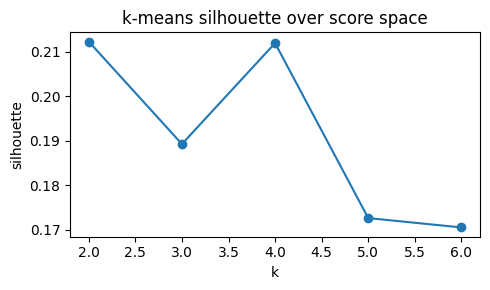

In [51]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = model.scores[:, : min(5, model.n_modes)]
ks = range(2, min(7, len(cohort)))
sils = []
for kk in ks:
    labels = KMeans(n_clusters=kk, n_init=10, random_state=0).fit_predict(X)
    sils.append(silhouette_score(X, labels))
for kk, s in zip(ks, sils):
    print(f"k={kk}: silhouette={s:.3f}")
plt.figure(figsize=(5, 3))
plt.plot(list(ks), sils, "o-"); plt.xlabel("k"); plt.ylabel("silhouette")
plt.title("k-means silhouette over score space"); plt.tight_layout(); plt.show()

### Mean shape ± sd along the first modes ("animate and name")

Walk the mean along each mode and **export the deformed surfaces** as PLY meshes:
`shape = mean + c · √eigenvalue · mode` for `c ∈ {−3, −2, 0, +2, +3}`. Using √eigenvalue
scales each step to that mode's natural SD, so ±3 SD spans the realistic range. All meshes
reuse the **mean's convex-hull connectivity**, so vertex *j* is the same point everywhere —
load `mode1_-3sd / _+0sd / _+3sd` together in 3D Slicer or ParaView (or animate `c`) and name
the mode by *where and how* the surface moves: size, elongation, AP/LR flattening, base–apex
asymmetry.

> **Units:** `mode_shape` works on the Procrustes-aligned coordinates, and `gpa(scale=True)`
> normalises every shape to unit Frobenius norm — so these coordinates (and the displacement
> table below) are **normalized, not mm**. That's why the magnitudes are ~0.0x. The shapes
> are still correct *up to a global scale*; only absolute size is gone (by design).

wrote 25 meshes to ../shapeworks_work_alldata_1024p/mode_shapes/  (open mode<k>_-3sd/_+0sd/_+3sd together)


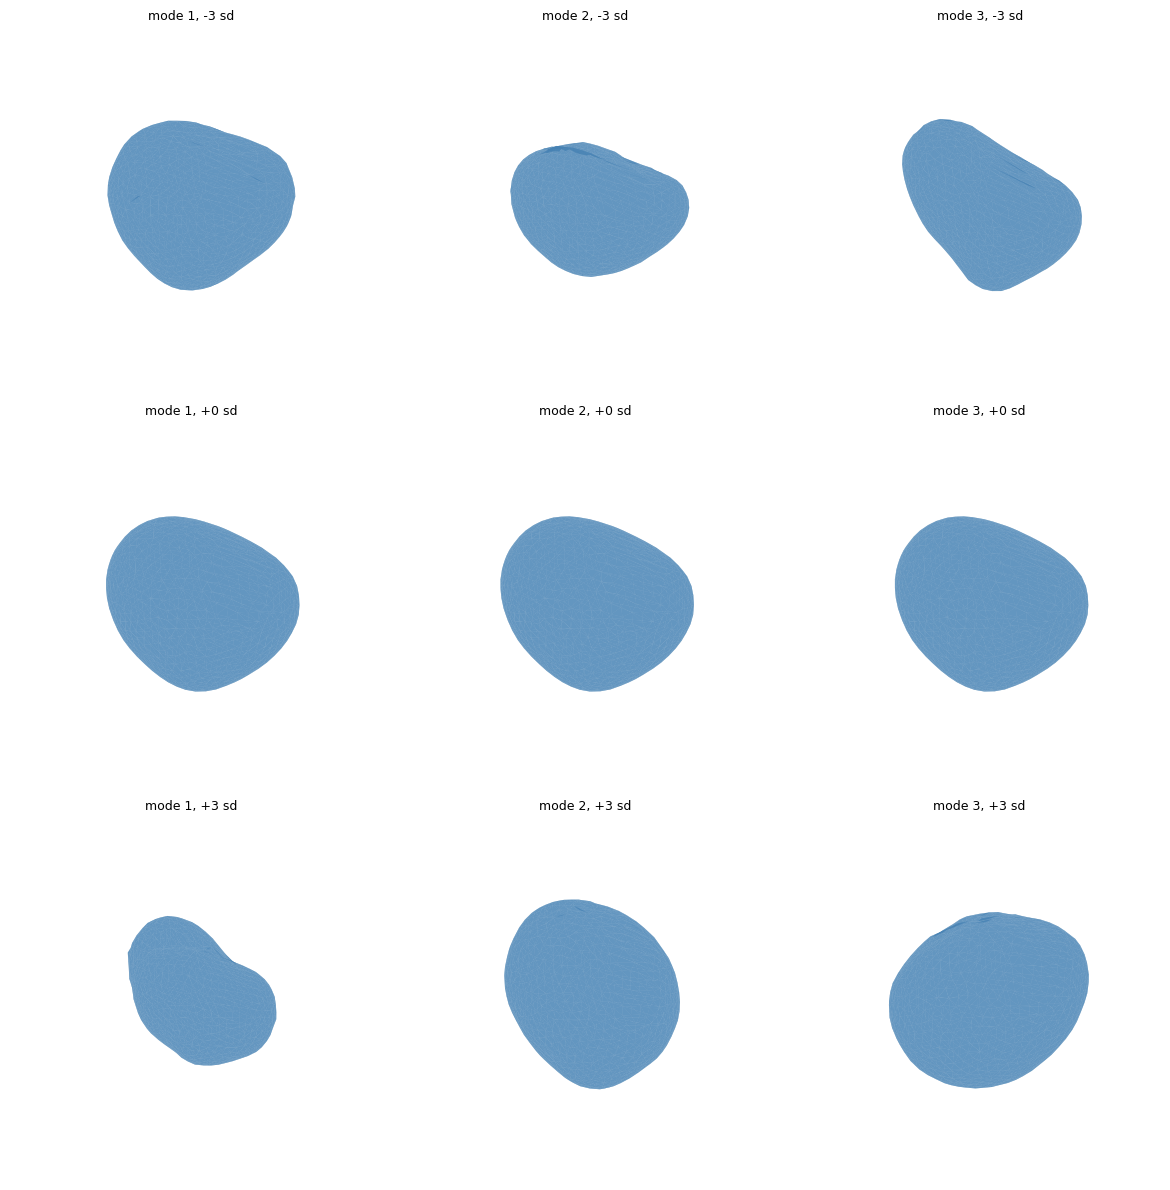


mode    var ratio   RMS disp +2sd   max disp +2sd  (normalized units)
-----------------------------------------------------------------
1           0.261          0.0043          0.0085
2           0.135          0.0031          0.0069
3           0.094          0.0026          0.0053


In [52]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from shape_modeling.analysis import export_mode_shapes, hull_surface

# 1. Export deformed surfaces for the first 5 modes at -3/-2/0/+2/+3 sd -> PLY for Slicer/ParaView.
ply_dir = WORK_DIR / "mode_shapes"
paths = export_mode_shapes(model, ply_dir, n_modes=min(5, model.n_modes))
print(f"wrote {len(paths)} meshes to {ply_dir}/  (open mode<k>_-3sd/_+0sd/_+3sd together)")

# 2. Inline preview: render the actual surface (mean hull faces, reused across the sweep).
faces = hull_surface(model.mean).faces
n_modes_viz = min(3, model.n_modes)
sds_viz = (-3.0, 0.0, 3.0)
fig = plt.figure(figsize=(4 * n_modes_viz, 4 * len(sds_viz)))
for row, sd in enumerate(sds_viz):
    for col in range(n_modes_viz):
        pts = mode_shape(model, col, sd)
        ax = fig.add_subplot(len(sds_viz), n_modes_viz, row * n_modes_viz + col + 1, projection="3d")
        mesh = Poly3DCollection(pts[faces], alpha=0.6, facecolor="steelblue", edgecolor="none")
        ax.add_collection3d(mesh)
        lim = np.abs(pts).max() * 1.05
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim))
        ax.set_title(f"mode {col+1}, {sd:+.0f} sd", fontsize=9)
        ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
plt.tight_layout(); plt.show()

# 3. How much does each mode move the surface? Per-particle displacement of +2 sd vs the mean.
#    NOTE: normalized units (gpa scale=True), NOT mm -- see the units note above.
mean_pts = mode_shape(model, 0, 0.0)   # sd=0 -> the mean shape (mode index irrelevant)
print(f"\n{'mode':<6}{'var ratio':>11}{'RMS disp +2sd':>16}{'max disp +2sd':>16}  (normalized units)")
print("-" * 65)
for m in range(n_modes_viz):
    disp = np.linalg.norm(mode_shape(model, m, 2.0) - mean_pts, axis=1)
    print(f"{m+1:<6}{model.explained_variance_ratio[m]:>11.3f}"
          f"{np.sqrt((disp**2).mean()):>16.4f}{disp.max():>16.4f}")


### Save the mean shape (warped real surface — not a convex hull)

Particles carry no faces, so to mesh the mean we have to get connectivity from somewhere.
A **convex hull** of the mean cloud is wrong for an organ: it keeps only the extreme points
and bridges every concavity (base notch, apex taper) → a faceted balloon. Instead we borrow
faces from a **real** surface: take the most "average" subject's groomed surface (watertight,
concave, full-resolution) and **thin-plate-spline warp** it so its particles land on the model
mean (`warp_surface`). Detail and concavities survive, and the result stays in the model's
**normalized GPA frame**, so it still overlays on the `mode<k>_+0sd.ply` files.

The reference subject's `*_local.particles` are used because they live in the **same frame** as
its groomed distance-transform surface (`*_world.particles` are Procrustes-rotated to the common
frame that builds `model.mean`).

**Two files are written.** `mean_shape.ply` (*coarse*) stays in the model's normalized GPA frame so
it overlays the `mode<k>_+0sd.ply` files — but it keeps the template gland's surface texture and
marching-cubes faceting, so it looks bumpy next to Studio's reconstructed mean.
`mean_shape_mm_smooth.ply` (*smooth*) is warped onto the raw world-particle mean — the exact shape,
in **millimetres**, that ShapeWorks Studio displays — then Taubin-smoothed (`smooth_surface`): the
clean "walnut" that overlays 1:1 on a mean exported from Studio (ComBat does not move the mean, so it
matches `model`).

In [53]:
import SimpleITK as sitk
from skimage import measure

from shape_modeling.analysis import Surface, save_ply, smooth_surface, warp_surface

# Reference subject = the one whose (world) particles are closest to the mean -> most "average".
mean_world = system.particles.mean(0)
ref_i = int(np.argmin(np.linalg.norm(system.particles - mean_world, axis=(1, 2))))
ref_id = system.case_ids[ref_i]
stem = ref_id.replace("/", "__").replace("\\", "__")   # same sanitisation as the ShapeWorks run

# Its groomed surface: marching cubes at the 0 level-set of the distance transform, mapped to
# the DT's physical frame (the frame the *_local.particles live in).
dt = sitk.ReadImage(str(WORK_DIR / "groomed" / f"{stem}_DT.nrrd"))
vz, faces, *_ = measure.marching_cubes(sitk.GetArrayFromImage(dt).astype(np.float32), level=0.0)
ref_verts = np.array(  # marching cubes returns (z,y,x); SimpleITK indexes (x,y,z)
    [dt.TransformContinuousIndexToPhysicalPoint(tuple(map(float, p))) for p in vz[:, ::-1]]
)
ref_mesh = Surface(verts=ref_verts, faces=faces.astype(np.int64))
ref_local = np.loadtxt(next(WORK_DIR.rglob(f"{stem}_DT_local.particles")))

# (a) COARSE -> mean_shape.ply. Warp the real surface onto the model mean (local frame ->
# normalized GPA frame). smoothing > 0 is essential: with smoothing=0 the spline interpolates
# *exactly* through every particle and ShapeWorks correspondence noise makes it oscillate between
# control points. Stays in the model's normalized frame, so it overlays the mode<k>_+0sd.ply files
# -- but it KEEPS the template gland's surface texture + marching-cubes faceting, so it looks bumpy
# next to Studio's reconstructed mean. Tuned for the normalized frame (coords ~0.0x).
mean_surf = warp_surface(ref_mesh, ref_local, model.mean, smoothing=1e-2)
save_ply(mean_surf, WORK_DIR / "mean_shape.ply")
print(f"wrote mean_shape.ply (coarse, normalized frame): {len(mean_surf.verts)} verts "
      f"(template subject {ref_id})")

# (b) SMOOTH -> mean_shape_mm_smooth.ply. Same warp but onto the raw WORLD-particle mean (the exact
# shape, in millimetres, that ShapeWorks Studio displays), then Taubin-smoothed to strip the
# template's high-frequency bumps + facets while preserving the gross shape. This is the clean
# "walnut" to overlay 1:1 on a mean exported from Studio (no rescaling). Larger spline smoothing
# because the target is mm-scale, not ~0.0x. ComBat does not move the mean, so this matches `model`.
mean_mm = warp_surface(ref_mesh, ref_local, mean_world, smoothing=5.0)
mean_mm_smooth = smooth_surface(mean_mm)
save_ply(mean_mm_smooth, WORK_DIR / "mean_shape_mm_smooth.ply")
print(f"wrote mean_shape_mm_smooth.ply (smooth, mm, Studio frame): {len(mean_mm_smooth.verts)} verts")

ImportError: cannot import name 'smooth_surface' from 'shape_modeling.analysis' (/Users/zoereinke/Repositories/ShapeModeling/src/shape_modeling/analysis/__init__.py)

### Is mode 1 a size mode? (the rigorous check)

Eyeballing the renders names the modes; this confirms the *size* one numerically. `gpa(scale=True)`
already removed scale, so the centroid size of the **aligned** shapes is ~constant — useless to
correlate. Instead correlate each mode's score against the **raw** (pre-Procrustes) centroid size,
and against gland volume. A near-±1 correlation = that mode tracks size. If scale was removed yet
mode 1 *still* correlates with size, that's the interesting case worth noting.

In [ ]:
from scipy import stats

from shape_modeling.analysis import centroid_size

raw_size = centroid_size(system.particles)   # pre-GPA centroid size (physical mm)
print(f"raw centroid size: mean {raw_size.mean():.1f}, cv {raw_size.std()/raw_size.mean():.2f}")
print(f"aligned centroid size cv (≈0 by construction): "
      f"{centroid_size(aligned).std()/centroid_size(aligned).mean():.4f}\n")

print(f"{'mode':<6}{'var':>7}{'r vs raw size':>16}{'p':>11}{'r vs volume':>16}{'p':>11}")
print("-" * 67)
for m in range(min(5, model.n_modes)):
    rs, ps = stats.pearsonr(model.scores[:, m], raw_size)
    rv, pv = stats.pearsonr(model.scores[:, m], volumes)
    flag = "  <- size mode" if max(abs(rs), abs(rv)) > 0.7 else ""
    print(f"{m+1:<6}{model.explained_variance_ratio[m]:>7.2f}"
          f"{rs:>+16.3f}{ps:>11.1e}{rv:>+16.3f}{pv:>11.1e}{flag}")


raw centroid size: mean 736.5, cv 0.18
aligned centroid size cv (≈0 by construction): 0.0000

mode      var   r vs raw size          p     r vs volume          p
-------------------------------------------------------------------
1        0.26          +0.404    1.1e-10          +0.320    4.9e-07
2        0.14          -0.133    4.1e-02          -0.058    3.7e-01
3        0.09          +0.060    3.6e-01          +0.119    6.7e-02
4        0.08          -0.038    5.6e-01          -0.005    9.4e-01
5        0.07          +0.033    6.2e-01          +0.034    6.1e-01


### How does size *align* with the PCA components?

The check above is **statistical** — do larger subjects sit at one end of a mode (score vs raw
centroid size). This adds the **geometric** view: pure isotropic growth moves every point radially
out from the centroid, i.e. along the **centred mean shape**. Treat that unit direction as a vector
in the 3·M shape space and take its cosine with each principal component (the components are
orthonormal). `Σ cos²` over all modes is the fraction of the growth direction that lives in the
model's span. If scale was truly removed, no single mode should align strongly and the growth
direction should be smeared thinly across many low-variance modes.

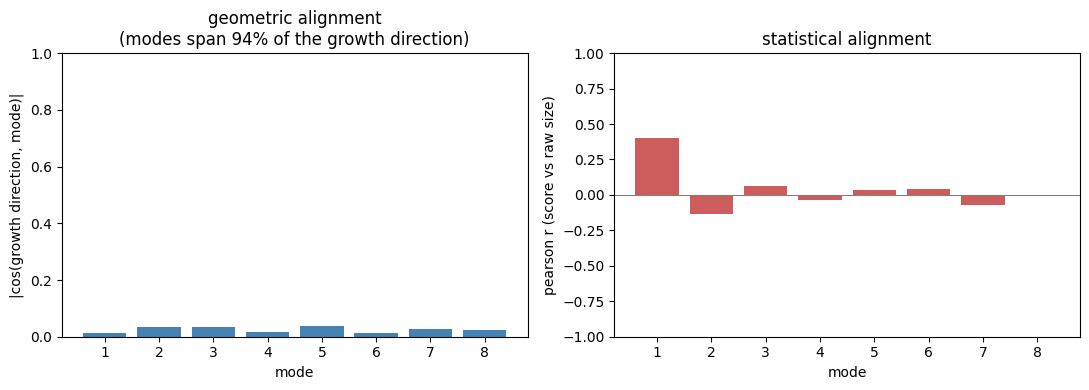

growth direction captured by the 235 modes: 94.4%
most size-aligned mode  (geometric |cos|): mode 32  (0.384)
most size-correlated mode (score vs size): mode 1  (+0.404)
=> no single dominant size mode


In [ ]:
# geometric: cosine of each PCA component with the isotropic-growth (size) direction
size_dir = (model.mean - model.mean.mean(0)).reshape(-1)
size_dir = size_dir / np.linalg.norm(size_dir)
cos_align = model.components @ size_dir            # (K,) components are orthonormal rows
captured = float((cos_align ** 2).sum())           # fraction of the size direction in the model span

# statistical: score-vs-raw-size correlation per mode (raw_size from the cell above)
r_size = np.array([stats.pearsonr(model.scores[:, m], raw_size)[0] for m in range(model.n_modes)])

k = min(8, model.n_modes)
x = np.arange(1, k + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(x, np.abs(cos_align[:k]), color="steelblue")
ax1.set(xlabel="mode", ylabel="|cos(growth direction, mode)|", ylim=(0, 1),
        title=f"geometric alignment\n(modes span {captured:.0%} of the growth direction)")
ax2.bar(x, r_size[:k], color="indianred"); ax2.axhline(0, c="grey", lw=0.8)
ax2.set(xlabel="mode", ylabel="pearson r (score vs raw size)", ylim=(-1, 1),
        title="statistical alignment")
plt.tight_layout(); plt.show()

g, s = int(np.argmax(np.abs(cos_align))) + 1, int(np.argmax(np.abs(r_size))) + 1
print(f"growth direction captured by the {model.n_modes} modes: {captured:.1%}")
print(f"most size-aligned mode  (geometric |cos|): mode {g}  ({np.abs(cos_align).max():.3f})")
print(f"most size-correlated mode (score vs size): mode {s}  ({np.abs(r_size).max():+.3f})")
print("=> no single dominant size mode" if max(np.abs(cos_align).max(), np.abs(r_size).max()) < 0.7
      else f"=> mode {g if np.abs(cos_align).max() >= np.abs(r_size).max() else s} carries size")


## 6. Site / acquisition effect (test it, don't eyeball it)

Section 5's source colouring and silhouette are *descriptive*. A site effect is usually a
**continuous shift** along a mode — no clusters, small mean gaps — yet still systematic, and it
can hide past mode 3. So test it directly, on the **raw** `model_raw` (the un-harmonized baseline),
then confirm section 4's ComBat removed it. Three questions:

1. **Does source structure each mode?** Kruskal–Wallis per mode across the sources (non-parametric
   one-way ANOVA — scores aren't normal and groups are unequal, n = 12–56), with an ε² effect size.
   Run it twice: across **all** sources (acquisition + annotation mixed), and **within SAML only**
   (5 centres, one annotation protocol → isolates pure *acquisition site*). A Mann–Whitney of
   Prostate158 vs SAML gives the dataset/annotation axis on its own. Bonferroni-correct over the
   modes tested.
2. **What is the mechanism?** Re-group SAML by receive coil (endorectal vs surface) and report a
   Welch-t p + η² per mode — a defensible physical cause, not an opaque centre label.
3. **Did we remove it?** Section 4 already ran ComBat on the coordinates (protecting size); the
   before/after table at the end of this section compares `model_raw` → `model` to confirm site
   structure drops out while the size correlation survives.

> This is the **descriptive** all-data basis (healthy + cancer pooled). Cancer is confounded with
> source here (all cancer is Prostate158), so the cancer question belongs in the Prostate158-only
> grouped run; ComBat on centre does not change that. It only de-confounds the *between-site*
> anatomy.

In [ ]:
from scipy import stats

K = min(10, model_raw.n_modes)                                  # test the leading modes (where var lives)
center = np.array([s.split(":")[-1] for s in sources])      # BIDMC/BMC/HK/RUNMC/UCL/Prostate158
is_saml = np.array([s.startswith("SAML:") for s in sources])

def kruskal_eps2(labels, col):
    """Kruskal-Wallis across the groups in `labels`; returns (p, epsilon^2 effect size in [0,1])."""
    groups = [col[labels == g] for g in np.unique(labels)]
    groups = [g for g in groups if len(g) > 0]
    H, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    return p, H / (n - 1)                                   # epsilon^2 = H/(n-1)

alpha = 0.05 / K                                            # Bonferroni over the K modes tested
print(f"Kruskal-Wallis per mode   (Bonferroni alpha = 0.05/{K} = {alpha:.1e})\n")
print(f"{'mode':<5}{'var%':>6}{'all-src p':>12}{'eps2':>7}{'SAML-only p':>13}{'eps2':>7}"
      f"{'P158-vs-SAML p':>16}")
print("-" * 66)
for m in range(K):
    col = model_raw.scores[:, m]
    p_all, e_all = kruskal_eps2(center, col)                # acquisition + annotation mixed
    p_sml, e_sml = kruskal_eps2(center[is_saml], col[is_saml])   # pure acquisition site (1 protocol)
    _, p_ds = stats.mannwhitneyu(col[~is_saml], col[is_saml])    # dataset/annotation axis
    flag = "  <- source" if p_all < alpha else ""
    print(f"{m+1:<5}{model_raw.explained_variance_ratio[m]*100:>5.1f}{p_all:>12.2e}{e_all:>7.2f}"
          f"{p_sml:>13.2e}{e_sml:>7.2f}{p_ds:>16.2e}{flag}")

print("\nall-src      = any of the sources differ (acquisition + annotation mixed).")
print("SAML-only    = 5 centres under ONE annotation protocol -> isolates ACQUISITION SITE.")
print("P158-vs-SAML = dataset/annotation axis (Prostate158 TZ∪PZ union vs SAML single contour).")
print("eps2: ~0.01 negligible, ~0.06 medium, >0.14 large.  '<- source' = source structures that mode.")

Kruskal-Wallis per mode   (Bonferroni alpha = 0.05/10 = 5.0e-03)

mode   var%   all-src p   eps2  SAML-only p   eps2  P158-vs-SAML p
------------------------------------------------------------------
1     24.6    1.37e-02   0.06     7.74e-03   0.14        4.93e-01
2     13.9    2.42e-04   0.10     5.87e-01   0.03        2.51e-06  <- source
3     10.3    2.03e-07   0.17     1.16e-04   0.24        1.61e-03  <- source
4      9.1    1.72e-04   0.10     5.17e-04   0.21        2.63e-01  <- source
5      7.8    1.72e-03   0.08     3.36e-03   0.16        5.29e-01  <- source
6      6.3    4.99e-02   0.05     4.64e-02   0.10        1.95e-01
7      4.1    2.57e-03   0.08     9.17e-02   0.08        1.31e-03  <- source
8      2.6    4.57e-01   0.02     3.27e-01   0.05        8.81e-01
9      2.3    1.44e-02   0.06     9.42e-02   0.08        7.58e-03
10     1.7    8.35e-01   0.01     6.95e-01   0.02        9.68e-01

all-src      = any of the sources differ (acquisition + annotation mixed).
SAML-only

In [ ]:
# Mechanism: receive coil (within SAML only -- Prostate158 has no endorectal arm, so it's left out).
COIL = {"BIDMC": "endorectal", "BMC": "endorectal", "HK": "endorectal",
        "RUNMC": "surface", "UCL": "surface"}            # I2CVB (surface) already excluded from cohort
coil = np.array([COIL.get(c, "n/a") for c in center])
sel = np.isin(coil, ["endorectal", "surface"])

print("Coil mechanism within SAML   (endorectal BIDMC/BMC/HK  vs  surface RUNMC/UCL)\n")
print(f"{'mode':<5}{'endo mean':>11}{'surf mean':>11}{'Welch p':>11}{'eta2':>8}")
print("-" * 46)
for m in range(K):
    col = model_raw.scores[sel, m]; g = coil[sel]
    a, b = col[g == "endorectal"], col[g == "surface"]
    _, p = stats.ttest_ind(a, b, equal_var=False)
    grand = col.mean()
    ss_b = len(a) * (a.mean() - grand) ** 2 + len(b) * (b.mean() - grand) ** 2
    ss_t = ((col - grand) ** 2).sum()
    eta2 = ss_b / ss_t if ss_t > 0 else np.nan
    print(f"{m+1:<5}{a.mean():>+11.3f}{b.mean():>+11.3f}{p:>11.2e}{eta2:>8.3f}")

print("\neta2 = fraction of that mode's (within-SAML) variance explained by coil type.")
print("A mode with large coil eta2 is acquisition-driven, not anatomy -- harmonize before reading biology.")
print("Coil is ONE factor; if 'SAML-only' Kruskal above is significant where coil eta2 is small,")
print("other acquisition factors (field strength, vendor, resolution) are also in play -> harmonize on CENTRE.")

Coil mechanism within SAML   (endorectal BIDMC/BMC/HK  vs  surface RUNMC/UCL)

mode   endo mean  surf mean    Welch p    eta2
----------------------------------------------
1         +0.005     -0.012   2.01e-01   0.017
2         -0.023     -0.006   1.45e-01   0.021
3         -0.031     +0.012   2.02e-05   0.166
4         +0.002     +0.008   5.29e-01   0.004
5         -0.011     +0.012   1.37e-02   0.057
6         -0.003     -0.003   9.50e-01   0.000
7         +0.012     +0.002   8.79e-02   0.028
8         -0.000     -0.001   8.02e-01   0.001
9         -0.009     +0.001   1.10e-02   0.062
10        +0.002     -0.003   2.37e-01   0.015

eta2 = fraction of that mode's (within-SAML) variance explained by coil type.
A mode with large coil eta2 is acquisition-driven, not anatomy -- harmonize before reading biology.
Coil is ONE factor; if 'SAML-only' Kruskal above is significant where coil eta2 is small,
other acquisition factors (field strength, vendor, resolution) are also in play -> harmo

### Aside: the deterministic L/S core of ComBat (illustration on `model_raw`)

Location/scale (L/S) correction is the deterministic core of ComBat: per source, subtract that
source's additive shift and divide out its multiplicative scale on each mode, then restore the
pooled mean/var. (Full ComBat adds empirical-Bayes shrinkage of those per-source terms — it
matters most for *tiny* batches; here n = 12–56.) This cell applies it to the **scores** of the
raw `model_raw`, purely to illustrate the mechanism.

The before→after source p-value is **not a discovery** — L/S removes the tested group effect by
construction, so it *should* shoot up to ~1. The informative column is **size**: if the score–size
correlation survives, it removed site without erasing anatomy; if it *collapses*, size is entangled
with source and per-source standardization is also wiping out real size differences — the reason
real ComBat keeps biological covariates *in the model* as protected terms.

> The **production** harmonization (section 4) does the principled thing this aside only mimics: it
> corrects the particle **coordinates** and re-runs GPA + PCA, with raw size protected as a
> covariate. The next cell compares that real model (`model`) against `model_raw`.

In [ ]:
from shape_modeling.analysis import centroid_size

raw_size = centroid_size(system.particles)          # pre-GPA centroid size (mm) -- a biology proxy

def ls_harmonize(scores, labels):
    """ComBat-style location/scale: standardize each source to the pooled mean/var, per column."""
    out = scores.astype(float).copy()
    gmean, gstd = scores.mean(0), scores.std(0) + 1e-12
    for g in np.unique(labels):
        i = labels == g
        out[i] = (scores[i] - scores[i].mean(0)) / (scores[i].std(0) + 1e-12) * gstd + gmean
    return out

harm = ls_harmonize(model_raw.scores[:, :K], center)
print(f"{'mode':<5}{'src p before':>14}{'src p after':>13}{'r(size) before':>16}{'after':>9}")
print("-" * 57)
for m in range(K):
    pb, _ = kruskal_eps2(center, model_raw.scores[:, m])
    pa, _ = kruskal_eps2(center, harm[:, m])
    rb = stats.pearsonr(model_raw.scores[:, m], raw_size)[0]
    ra = stats.pearsonr(harm[:, m], raw_size)[0]
    print(f"{m+1:<5}{pb:>14.2e}{pa:>13.2e}{rb:>+16.3f}{ra:>+9.3f}")

print("\nsrc p after ~1 confirms L/S targeted source. If r(size) holds before->after, harmonization")
print("kept anatomy; if it collapses, size is confounded with source -> protect it as a covariate.")

mode   src p before  src p after  r(size) before    after
---------------------------------------------------------
1          1.37e-02     9.96e-01          +0.385   +0.381
2          2.42e-04     9.82e-01          -0.053   -0.091
3          2.03e-07     9.89e-01          +0.148   +0.046
4          1.72e-04     9.91e-01          +0.021   +0.054
5          1.72e-03     9.88e-01          +0.045   +0.075
6          4.99e-02     9.98e-01          +0.062   +0.052
7          2.57e-03     9.97e-01          -0.101   -0.039
8          4.57e-01     9.99e-01          +0.007   +0.003
9          1.44e-02     1.00e+00          -0.020   -0.093
10         8.35e-01     9.99e-01          +0.088   +0.091

src p after ~1 confirms L/S targeted source. If r(size) holds before->after, harmonization
kept anatomy; if it collapses, size is confounded with source -> protect it as a covariate.


### Before → after: did the section-4 ComBat remove site without erasing anatomy?

Compare the raw baseline `model_raw` against the canonical harmonized `model` (built in section 4)
on the re-fit PCA scores.

- **Source p** (Kruskal across the 6 sites): `*` flags should be present on the `model_raw`
  ("before") side and gone on the `model` ("after") side. Unlike the L/S-on-scores aside above,
  ComBat-on-coordinates does **not** null these to ~1 by construction; a large drop, not a flat
  line, is the expected result.
- **r(size)**: the size mode should hold its raw magnitude — anatomy kept. PCA mode sign is
  arbitrary, so compare |r|. A collapse toward 0 means size got entangled with site.

In [ ]:
# Production check: raw baseline (model_raw) -> canonical harmonized model (model), on re-fit scores.
# Re-uses kruskal_eps2 + center + raw_size from above. "before" = model_raw, "after" = model.
Kv = min(K, model.n_modes)
alpha_v = 0.05 / Kv
print(f"model_raw -> model (ComBat)   (Kruskal across {np.unique(center).size} sites; "
      f"Bonferroni alpha = {alpha_v:.1e})\n")
print(f"{'mode':<5}{'src p before':>14}{'src p after':>14}{'r(size) before':>16}{'r(size) after':>15}")
print("-" * 64)
for m in range(Kv):
    pb, _ = kruskal_eps2(center, model_raw.scores[:, m])
    pa, _ = kruskal_eps2(center, model.scores[:, m])
    rb = stats.pearsonr(model_raw.scores[:, m], raw_size)[0]
    ra = stats.pearsonr(model.scores[:, m], raw_size)[0]
    fb = "*" if pb < alpha_v else " "
    fa = "*" if pa < alpha_v else " "
    print(f"{m+1:<5}{pb:>13.2e}{fb}{pa:>13.2e}{fa}{rb:>+16.3f}{ra:>+15.3f}")

print("\n'*' = source significant at the Bonferroni threshold; the goal is '*' before, gone after.")
print("PCA mode sign is arbitrary -> compare |r(size)|: the size mode should hold its raw value.")
print("Caveat: the smallest sites have n=12, so the empirical-Bayes scale terms stay noisy. Expected.")

model_raw -> model (ComBat)   (Kruskal across 6 sites; Bonferroni alpha = 5.0e-03)

mode   src p before   src p after  r(size) before  r(size) after
----------------------------------------------------------------
1         1.37e-02      7.83e-01           +0.385         +0.404
2         2.42e-04*     8.74e-01           -0.053         -0.133
3         2.03e-07*     6.52e-01           +0.148         +0.060
4         1.72e-04*     8.78e-01           +0.021         -0.038
5         1.72e-03*     9.53e-01           +0.045         +0.033
6         4.99e-02      9.39e-01           +0.062         +0.039
7         2.57e-03*     7.42e-01           -0.101         -0.070
8         4.57e-01      9.94e-01           +0.007         -0.004
9         1.44e-02      8.43e-01           -0.020         -0.059
10        8.35e-01      9.99e-01           +0.088         +0.088

'*' = source significant at the Bonferroni threshold; the goal is '*' before, gone after.
PCA mode sign is arbitrary -> compare |r(size

## 7. Coil deformation as a deployment-prior proxy (endorectal ≈ ultrasound probe)

The downstream use of this model is a shape **prior for (transrectal) ultrasound**, where
suspected-cancer patients' glands are compressed by the probe. The endorectal-coil cases
(BMC / BIDMC / HK) are the *only* glands in this MRI cohort that carry rectal-compression
realism — the coil pushes from the rectum just as a TRUS probe does. So here, unlike section 6,
the coil effect is **signal to keep, not a confound to scrub**.

Two things make this analysis deliberately use the **un-harmonized** `model_raw` / raw particles,
**not** the canonical harmonized `model`:

- **ComBat-on-centre removes the coil difference by construction.** Coil is perfectly *nested* in
  centre (each site is wholly endo or wholly surface), so harmonizing site flattens this
  deformation back toward the undeformed mean. The harmonized `model` is right for the anatomy
  basis and **wrong** for seeing deformation.
- **Size is part of the deformation** (a squeezed gland reads smaller), so displacement is measured
  with `gpa(scale=False)` to keep millimetres.

The cell reports: **(1)** the per-point group-mean displacement endo-vs-surface in mm, with a
within-SAML cross-check that drops the Prostate158-vs-SAML dataset confound; **(2)** which
`model_raw` modes carry the difference and how low-dimensional it is — if a few modes capture it,
the prior can *reach* the deformed state by moving along existing modes (the reassuring property
for downstream fitting); **(3)** the two group-mean glands saved as `mean_endo_coil.ply` /
`mean_surface_coil.ply`, sharing vertex ordering with `mean_shape.ply` so you can load all three in
3D Slicer / ParaView and colour by vertex-to-vertex distance to **see where** the compression bites.

> **Caveat:** the endo sites (Boston BIDMC/BMC, Hong Kong HK) also differ in population and scanner
> from the surface sites, so the mm gap is coil **+ population + scanner**, not pure coil — a
> directional proxy for probe deformation, not a calibrated model of it. The within-SAML row narrows
> (but does not eliminate) that confound.


In [ ]:
# Coil = a deployment-prior proxy for ultrasound-probe deformation. Endorectal-coil glands
# (BMC/BIDMC/HK) are compressed from the rectum like a TRUS probe; surface-coil SAML + all
# Prostate158 are undeformed. Measured on the UN-harmonized data on purpose: the canonical
# `model` is ComBat-on-centre, and coil is perfectly NESTED in centre (each site is wholly endo
# or wholly surface), so harmonizing site flattens this deformation away. Size is part of the
# deformation, so displacement is in PHYSICAL mm -> gpa(scale=False).
import SimpleITK as sitk
from skimage import measure

from shape_modeling.analysis import Surface, save_ply, warp_surface

ENDO_SITES = {"BMC", "BIDMC", "HK"}
is_endo = np.isin(center, list(ENDO_SITES))          # surface group = SAML surface + Prostate158
print(f"endo-coil (deformed proxy): {is_endo.sum()}   surface / undeformed: {(~is_endo).sum()}\n")

# --- 1. group-mean displacement in mm (scale=False keeps size) -----------------------------------
aligned_mm, _ = gpa(system.particles, scale=False)
dmag = np.linalg.norm(aligned_mm[is_endo].mean(0) - aligned_mm[~is_endo].mean(0), axis=1)  # per-point mm
print("per-point displacement  endo vs surface  (mm):")
print(f"  mean {dmag.mean():.2f}   median {np.median(dmag):.2f}   p95 {np.percentile(dmag, 95):.2f}"
      f"   max {dmag.max():.2f}")
se, ss = np.median(raw_size[is_endo]), np.median(raw_size[~is_endo])
print(f"  raw centroid size:  endo {se:.0f}   surface {ss:.0f} mm   ({100 * (se / ss - 1):+.0f}%)")

# within-SAML cross-check: drops the Prostate158-vs-SAML dataset/annotation confound
saml = np.array([s.startswith("SAML:") for s in sources])
am_s, _ = gpa(system.particles[saml], scale=False)
endo_s = is_endo[saml]
ds = np.linalg.norm(am_s[endo_s].mean(0) - am_s[~endo_s].mean(0), axis=1)
print(f"  within-SAML only (no dataset confound):  mean {ds.mean():.2f}   median {np.median(ds):.2f} mm")

# --- 2. which model_raw modes carry the difference, and how low-dimensional is it? ---------------
# Rank the standardized score gap only over the LEADING modes (where variance lives, like the K in
# section 6) -- a tiny-variance high mode can show a large standardized gap purely by chance.
K_lead = min(10, model_raw.n_modes)
delta = (aligned_raw[is_endo].mean(0) - aligned_raw[~is_endo].mean(0)).reshape(-1)  # normalized frame
gap = (model_raw.scores[is_endo].mean(0) - model_raw.scores[~is_endo].mean(0)) / model_raw.scores.std(0)
print(f"\ntop modes separating endo vs surface (standardized score gap, over first {K_lead} modes):")
for m in np.argsort(-np.abs(gap[:K_lead]))[:5]:
    print(f"  mode {m + 1:>2}: {gap[m]:+.2f} sd   (var {model_raw.explained_variance_ratio[m] * 100:.1f}%)")
dvec = delta / np.linalg.norm(delta)
for k in (1, 3, 5):
    frac = float(np.sum((model_raw.components[:k] @ dvec) ** 2))   # components are orthonormal
    print(f"  first {k} modes capture {frac * 100:.0f}% of the displacement direction")
print("  (low-dimensional => the prior can REACH the deformed state along a few existing modes)")

# --- 3. save the two group-mean glands as viewable meshes (un-harmonized, normalized GPA frame) --
# Real surface for connectivity: most-average subject's groomed DT, TPS-warped onto each group mean
# (same recipe as the mean-shape cell). Group means taken in the normalized frame so all three PLYs
# (mean_shape / endo / surface) share vertex ordering -> overlay & colour-by-distance in Slicer.
ref_i = int(np.argmin(np.linalg.norm(system.particles - system.particles.mean(0), axis=(1, 2))))
stem = system.case_ids[ref_i].replace("/", "__").replace("\\", "__")
dt = sitk.ReadImage(str(WORK_DIR / "groomed" / f"{stem}_DT.nrrd"))
vz, faces, *_ = measure.marching_cubes(sitk.GetArrayFromImage(dt).astype(np.float32), level=0.0)
ref_verts = np.array(
    [dt.TransformContinuousIndexToPhysicalPoint(tuple(map(float, p))) for p in vz[:, ::-1]]
)
ref_mesh = Surface(verts=ref_verts, faces=faces.astype(np.int64))
ref_local = np.loadtxt(next(WORK_DIR.rglob(f"{stem}_DT_local.particles")))

for name, gm in [("endo_coil", aligned_raw[is_endo].mean(0)),
                 ("surface_coil", aligned_raw[~is_endo].mean(0))]:
    surf = warp_surface(ref_mesh, ref_local, gm, smoothing=1e-2)
    out = WORK_DIR / f"mean_{name}.ply"
    save_ply(surf, out)
    print(f"wrote {out.name}: {len(surf.verts)} verts (shares ordering with mean_shape.ply)")
print(f"template subject: {system.case_ids[ref_i]}  "
      "-> load mean_shape/endo/surface together and colour by vertex distance to see WHERE it bites")


endo-coil (deformed proxy): 54   surface / undeformed: 182

per-point displacement  endo vs surface  (mm):
  mean 1.98   median 1.84   p95 3.84   max 4.50
  raw centroid size:  endo 661   surface 745 mm   (-11%)
  within-SAML only (no dataset confound):  mean 2.67   median 2.52 mm

top modes separating endo vs surface (standardized score gap, over first 10 modes):
  mode  3: -0.89 sd   (var 10.3%)
  mode  2: -0.56 sd   (var 13.9%)
  mode  9: -0.54 sd   (var 2.3%)
  mode  7: +0.52 sd   (var 4.1%)
  mode  5: -0.37 sd   (var 7.8%)
  first 1 modes capture 1% of the displacement direction
  first 3 modes capture 78% of the displacement direction
  first 5 modes capture 85% of the displacement direction
  (low-dimensional => the prior can REACH the deformed state along a few existing modes)
wrote mean_endo_coil.ply: 9704 verts (shares ordering with mean_shape.ply)
wrote mean_surface_coil.ply: 9704 verts (shares ordering with mean_shape.ply)
template subject: UCL/Case28  -> load mean_shape/en